# X-IIoTID — 03. Network Feature Screening and Visual Quality Gate

**Project:** J26-CS-336 — lightweight network-based detection at an IIoT edge gateway  
**Stage:** feature participation and data-quality investigation (**before splitting and modelling**)

This notebook reads your real **X-IIoTID dataset.csv** in **chunks** (rather than loading all ~820k rows as strings into RAM). It generates:

1. A **68-column participation inventory** (candidate network, metadata, separate module, label, etc.).
2. Actual distributions of `class3`, `class2`, `class1` and their values.
3. Missing/placeholder percentages for candidate network features.
4. Numeric-conversion quality for fields expected to be numeric.
5. **Sample-based** network-feature collisions and possible conflicting labels.
6. Five visualizations (PNG) and CSV/JSON/Markdown reports under `network_flow_v2/reports` and `docs`.

**Important:** this notebook makes **no final feature selections**, does **not train any model**, and does **not modify the original CSV**. Features shared with ToN-IoT require separate semantic verification; timestamps and raw IP addresses are metadata only.

**Notebook path:** `network_flow_v2/notebooks/x_iiotid/03_x_iiotid_network_feature_screening.ipynb`. Run **Run All** inside VS Code using your V2 virtual-environment kernel.

In [2]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp312-cp312-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.67.0-cp312-cp312-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl (70 kB)
Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl (7.3 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
Note: you may need to restart the kernel to use updated packages.


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import matplotlib
import matplotlib.pyplot as plt

print("Matplotlib version:", matplotlib.__version__)
print("Matplotlib installed successfully!")

Matplotlib version: 3.11.2
Matplotlib installed successfully!


In [4]:
from pathlib import Path
from collections import Counter
import json
import re
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works from inside the Git-connected V2 project and from the original V2 tree.
candidates = [Path.cwd(), *Path.cwd().parents,
              Path(r"D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2"),
              Path(r"D:\J26-CS-336-Network-Flow-V2\network_flow_v2")]
ROOT = next((p for p in candidates if (p / 'data/raw/x_iiotid/X-IIoTID dataset.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        'Could not find data/raw/x_iiotid/X-IIoTID dataset.csv. '
        'Place the ORIGINAL CSV under the Git-connected network_flow_v2/data/raw/x_iiotid/ folder.'
    )
CSV = ROOT / 'data/raw/x_iiotid/X-IIoTID dataset.csv'
FIG = ROOT / 'reports/figures'
AUDIT = ROOT / 'reports/audits'
DOCS = ROOT / 'docs'
for directory in (FIG, AUDIT, DOCS):
    directory.mkdir(parents=True, exist_ok=True)

CHUNK_SIZE = 50_000
SAMPLE_PER_CHUNK = 2_500  # Approx. 5% across all portions of the file; only used for exploratory collision plots.
SEED = 336
PLACEHOLDERS = {'', '-', '?', 'n/a', 'na', 'nan', 'none', 'null', 'missing', 'unknown'}
print('Dataset:', CSV)
print('CSV size (MB):', round(CSV.stat().st_size / 1e6, 2))
print('Reports will be saved under:', ROOT)

Dataset: d:\J26-CS-336-Network-Flow-V2\network_flow_v2\data\raw\x_iiotid\X-IIoTID dataset.csv
CSV size (MB): 355.31
Reports will be saved under: d:\J26-CS-336-Network-Flow-V2\network_flow_v2


## A. Decide which columns could participate

**Feature:** an observable input such as flow duration, packet count, or connection state.  
**Label:** the expected answer (`Normal` or `Attack`) used for supervised training/evaluation—not an input.  
**Metadata:** descriptive information (time, raw IP) useful for filtering or grouping but excluded from the first model.  
**Leakage:** a shortcut that lets the model see the answer indirectly instead of learning deployable network behavior.

**Example in your research:** a gateway can measure `Scr_pkts`, but it might not know `anomaly_alert` without running another detector; training on that alert risks measuring someone else's IDS rather than your own detection.  
**Everyday example:** teaching a student with an exam paper that already includes the correct answers is leakage.

Roles are **proposed** and based on exact columns actually present; unknown names are marked **REVIEW_SEPARATELY**, not silently selected. These roles do not imply a feature has been validated for edge deployment.

In [5]:
def key(name):
    return re.sub(r'[^a-z0-9]+', '', str(name).casefold())

header = pd.read_csv(CSV, nrows=0).columns.tolist()
lookup = {key(c): c for c in header}

def existing(*names):
    return [lookup[key(name)] for name in names if key(name) in lookup]

NETWORK_CORE = [
    'Protocol', 'Service', 'Duration', 'Scr_bytes', 'Des_bytes',
    'Scr_pkts', 'Des_pkts', 'Scr_ip_bytes', 'Des_ip_bytes',
    'Conn_state', 'is_syn_only', 'is_SYN_ACK', 'is_pure_ack',
    'is_with_payload', 'FIN or RST', 'total_bytes', 'total_packet',
    'paket_rate', 'byte_rate',
]
NETWORK_OPTIONAL = [
    'missed_bytes', 'Scr_bytes_ratio', 'Des_bytes_ratio',
    'Scr_packs_ratio', 'Scr_packts_ratio', 'Des_pkts_ratio',
    'Scr_pkts_ratio',
]
PORT_EXPERIMENT = ['Scr_port', 'Des_port']
METADATA = ['Date', 'Timestamp', 'Scr_IP', 'Des_IP']
LABELS = ['class1', 'class2', 'class3']
EXCLUDE_CONSTANT = ['Bad_checksum', 'is_SYN_with_RST']
EXCLUDE_ALERT = ['anomaly_alert', 'OSSEC_alert', 'OSSEC_alert_level']

role_order = [
    ('LABEL_ONLY', LABELS),
    ('METADATA_ONLY', METADATA),
    ('EXCLUDE_CONSTANT_CHECK', EXCLUDE_CONSTANT),
    ('EXCLUDE_EXISTING_ALERT', EXCLUDE_ALERT),
    ('NETWORK_CORE_CANDIDATE', NETWORK_CORE),
    ('NETWORK_OPTIONAL_CANDIDATE', NETWORK_OPTIONAL),
    ('PORT_ABLATION_ONLY', PORT_EXPERIMENT),
]
role_map = {}
for role, names in role_order:
    for name in names:
        if key(name) in lookup:
            col = lookup[key(name)]
            if col in role_map:
                raise ValueError('Column assigned multiple roles: ' + col)
            role_map[col] = role

inventory = pd.DataFrame([
    {'column_number': i, 'original_column': c,
     'proposed_role': role_map.get(c, 'REVIEW_SEPARATELY'),
     'gateway_measurable_verified': 'NO',
     'semantic_definition_verified': 'NO',
     'model_input_now': 'NO — screening only'}
    for i, c in enumerate(header, 1)
])
print('Actual column count:', len(header))
print('Column roles:')
display(inventory['proposed_role'].value_counts().rename_axis('role').to_frame('count'))
display(inventory)

core_cols = [c for c in header if role_map.get(c) == 'NETWORK_CORE_CANDIDATE']
optional_cols = [c for c in header if role_map.get(c) == 'NETWORK_OPTIONAL_CANDIDATE']
network_cols = [c for c in header if role_map.get(c) in {
    'NETWORK_CORE_CANDIDATE','NETWORK_OPTIONAL_CANDIDATE','PORT_ABLATION_ONLY'}]
label_cols = existing(*LABELS)
assert 'class3' in [c.casefold() for c in label_cols], 'Binary class3 label not found — inspect columns.'
print('Existing core network candidates:', len(core_cols), core_cols)
print('Existing optional network candidates:', len(optional_cols), optional_cols)
print('Labels:', label_cols)
print('Columns requiring manual review:', inventory.query("proposed_role == 'REVIEW_SEPARATELY'")['original_column'].tolist())

Actual column count: 68
Column roles:


,count
role,
REVIEW_SEPARATELY,30
NETWORK_CORE_CANDIDATE,19
NETWORK_OPTIONAL_CANDIDATE,5
METADATA_ONLY,4
EXCLUDE_EXISTING_ALERT,3
LABEL_ONLY,3
PORT_ABLATION_ONLY,2
EXCLUDE_CONSTANT_CHECK,2


,column_number,original_column,proposed_role,gateway_measurable_verified,semantic_definition_verified,model_input_now
0,1,Date,METADATA_ONLY,NO,NO,NO — screening only
1,2,Timestamp,METADATA_ONLY,NO,NO,NO — screening only
2,3,Scr_IP,METADATA_ONLY,NO,NO,NO — screening only
3,4,Scr_port,PORT_ABLATION_ONLY,NO,NO,NO — screening only
4,5,Des_IP,METADATA_ONLY,NO,NO,NO — screening only
...,...,...,...,...,...,...
63,64,read_write_physical.process,REVIEW_SEPARATELY,NO,NO,NO — screening only
64,65,is_privileged,REVIEW_SEPARATELY,NO,NO,NO — screening only
65,66,class1,LABEL_ONLY,NO,NO,NO — screening only
66,67,class2,LABEL_ONLY,NO,NO,NO — screening only


Existing core network candidates: 19 ['Protocol', 'Service', 'Duration', 'Scr_bytes', 'Des_bytes', 'Conn_state', 'is_syn_only', 'Is_SYN_ACK', 'is_pure_ack', 'is_with_payload', 'FIN or RST', 'Scr_pkts', 'Scr_ip_bytes', 'Des_pkts', 'Des_ip_bytes', 'total_bytes', 'total_packet', 'paket_rate', 'byte_rate']
Existing optional network candidates: 5 ['missed_bytes', 'Scr_packts_ratio', 'Des_pkts_ratio', 'Scr_bytes_ratio', 'Des_bytes_ratio']
Labels: ['class1', 'class2', 'class3']
Columns requiring manual review: ['Avg_user_time', 'Std_user_time', 'Avg_nice_time', 'Std_nice_time', 'Avg_system_time', 'Std_system_time', 'Avg_iowait_time', 'Std_iowait_time', 'Avg_ideal_time', 'Std_ideal_time', 'Avg_tps', 'Std_tps', 'Avg_rtps', 'Std_rtps', 'Avg_wtps', 'Std_wtps', 'Avg_ldavg_1', 'Std_ldavg_1', 'Avg_kbmemused', 'Std_kbmemused', 'Avg_num_Proc/s', 'Std_num_proc/s', 'Avg_num_cswch/s', 'std_num_cswch/s', 'Login_attempt', 'Succesful_login', 'File_activity', 'Process_activity', 'read_write_physical.process'

## B. Scan all dataset records efficiently

For each column, **missing rate** = percentage of entries that are blank or placeholders such as `-` or `?`.  
A connection with no source byte count is **not automatically a zero-byte connection**: zero means measured value 0, while `-` often means no value was recorded.

We calculate full-dataset counts for missing values and labels. The **collision check uses only a reproducible sample**; it is not a final splitting rule.

In [6]:
missing_counts = Counter()
label_counts = {label: Counter() for label in label_cols}
nonmissing_counts = Counter()
numeric_good_counts = Counter()
row_total = 0
sample_parts = []

numeric_expected = existing(
    'Duration','Scr_bytes','Des_bytes','Scr_pkts','Des_pkts',
    'Scr_ip_bytes','Des_ip_bytes','missed_bytes','total_bytes',
    'total_packet','paket_rate','byte_rate','Scr_bytes_ratio',
    'Des_bytes_ratio','Scr_packs_ratio','Scr_packts_ratio',
    'Des_pkts_ratio','Scr_pkts_ratio','Scr_port','Des_port'
)

for i, chunk in enumerate(pd.read_csv(CSV, chunksize=CHUNK_SIZE,
                                       dtype=str, keep_default_na=False,
                                       low_memory=False)):
    chunk = chunk.fillna('')
    row_total += len(chunk)
    # Strip whitespace, normalize ONLY for quality calculations; original CSV untouched.
    stripped = chunk.apply(lambda col: col.astype(str).str.strip())
    invalid = stripped.apply(lambda col: col.str.lower().isin(PLACEHOLDERS))
    missing_counts.update(invalid.sum(axis=0).to_dict())
    for label in label_cols:
        label_counts[label].update(stripped[label].value_counts(dropna=False).to_dict())
    for col in numeric_expected:
        usable = stripped[col].mask(invalid[col])
        nonmissing_counts[col] += int(usable.notna().sum())
        numeric_good_counts[col] += int(pd.to_numeric(usable, errors='coerce').notna().sum())
    # Reproducible stratified-across-file exploratory sample (not by label).
    sampled = stripped.sample(n=min(SAMPLE_PER_CHUNK, len(stripped)),
                              random_state=SEED + i)
    sample_parts.append(sampled)
    if (i + 1) % 5 == 0:
        print(f'Processed {row_total:,} rows...')

sample = pd.concat(sample_parts, ignore_index=True)
missing_pct = pd.Series({col: 100 * missing_counts[col] / row_total for col in header})
numeric_pct = pd.Series({col: 100 * numeric_good_counts[col] / nonmissing_counts[col]
                         if nonmissing_counts[col] else np.nan
                         for col in numeric_expected})
inventory['missing_pct_all_rows'] = inventory['original_column'].map(missing_pct)
inventory['numeric_parse_pct_among_present'] = inventory['original_column'].map(numeric_pct)
print('Total rows scanned:', f'{row_total:,}')
print('Exploratory sample size:', f'{len(sample):,}')
print('Binary label distribution (verbatim):', label_counts[lookup['class3']])
for label in label_cols:
    print(f'\n{label} unique labels:', len(label_counts[label]))
    print(label_counts[label].most_common(22))

Processed 250,000 rows...
Processed 500,000 rows...
Processed 750,000 rows...
Total rows scanned: 820,834
Exploratory sample size: 42,500
Binary label distribution (verbatim): Counter({'Normal': 421417, 'Attack': 399417})

class1 unique labels: 19
[('Normal', 421417), ('RDOS', 141261), ('Scanning_vulnerability', 52852), ('Generic_scanning', 50277), ('BruteForce', 47241), ('MQTT_cloud_broker_subscription', 23524), ('Discovering_resources', 23148), ('Exfiltration', 22134), ('insider_malcious', 17447), ('Modbus_register_reading', 5953), ('False_data_injection', 5094), ('C&C', 2863), ('Dictionary', 2572), ('TCP Relay', 2119), ('fuzzing', 1313), ('Reverse_shell', 1016), ('crypto-ransomware', 458), ('MitM', 117), ('Fake_notification', 28)]

class2 unique labels: 10
[('Normal', 421417), ('RDOS', 141261), ('Reconnaissance', 127590), ('Weaponization', 67260), ('Lateral _movement', 31596), ('Exfiltration', 22134), ('Tampering', 5122), ('C&C', 2863), ('Exploitation', 1133), ('crypto-ransomware', 

## C. Visual reports

All plots show **actual results from your CSV when you run the notebook**, and are saved to `reports/figures/`. No synthetic scores, fabricated accuracy, or inferred APT detection results.

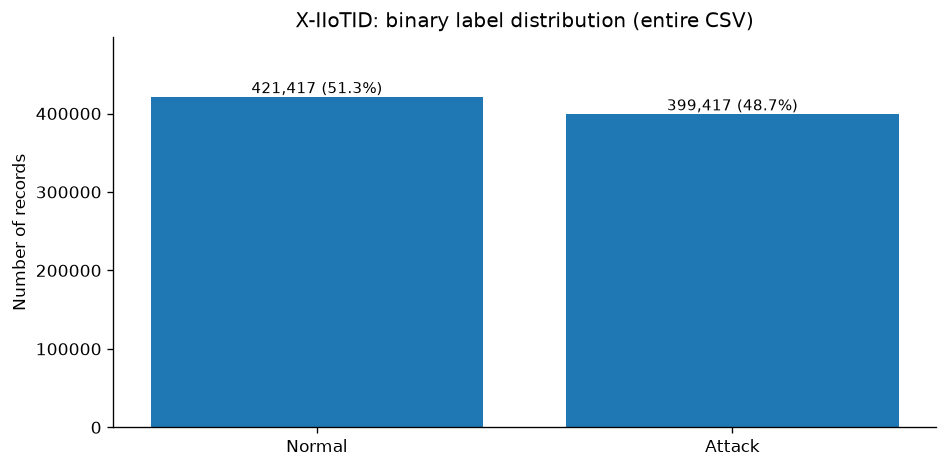

Saved: reports\figures\x_iiotid_binary_label_balance_v1.png


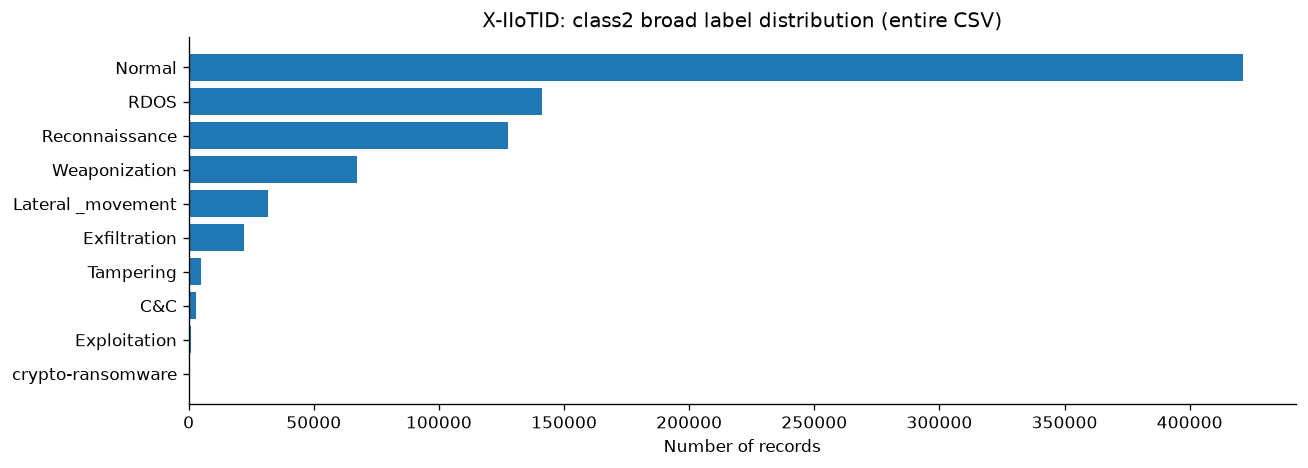

Saved: reports\figures\x_iiotid_class2_distribution_v1.png


In [7]:
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180,
                     'axes.spines.top': False, 'axes.spines.right': False})

def savefig(name):
    path = FIG / name
    plt.savefig(path, bbox_inches='tight')
    plt.show()
    print('Saved:', path.relative_to(ROOT))

binary = label_counts[lookup['class3']]
fig, ax = plt.subplots(figsize=(8, 4))
keys = [k for k, _ in binary.most_common()]
counts = [binary[k] for k in keys]
bars = ax.bar(keys, counts)
for bar, value in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f'{value:,} ({value/row_total:.1%})',
            ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, max(counts) * 1.18)
ax.set_title('X-IIoTID: binary label distribution (entire CSV)')
ax.set_ylabel('Number of records')
fig.tight_layout()
savefig('x_iiotid_binary_label_balance_v1.png')

broad = label_counts[lookup['class2']]
items = broad.most_common()
fig, ax = plt.subplots(figsize=(11, max(4, len(items) * 0.38)))
ax.barh([str(k) for k, _ in items[::-1]], [v for _, v in items[::-1]])
ax.set_title('X-IIoTID: class2 broad label distribution (entire CSV)')
ax.set_xlabel('Number of records')
fig.tight_layout()
savefig('x_iiotid_class2_distribution_v1.png')

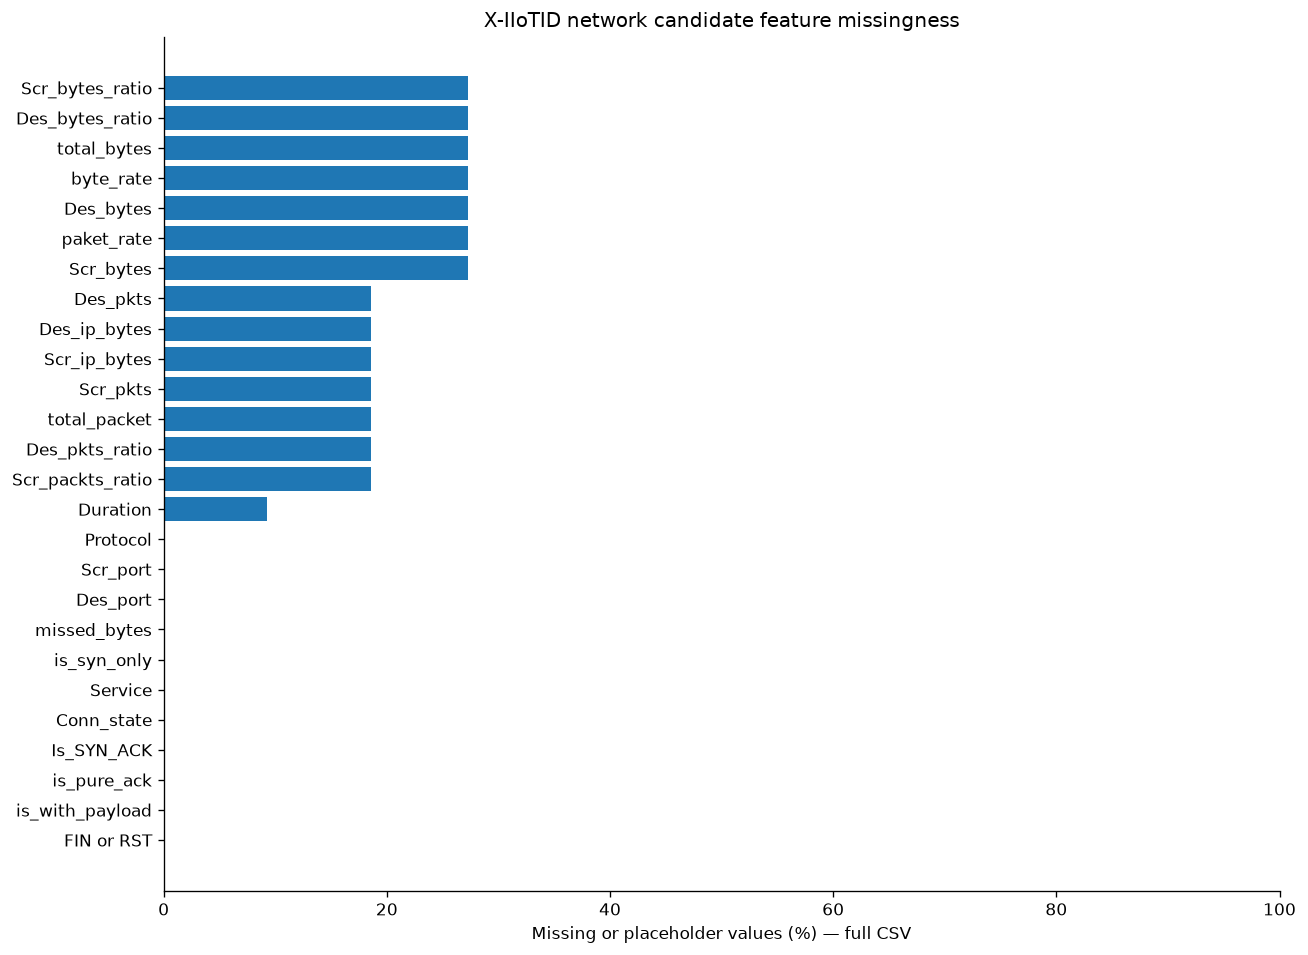

Saved: reports\figures\x_iiotid_network_missingness_v1.png


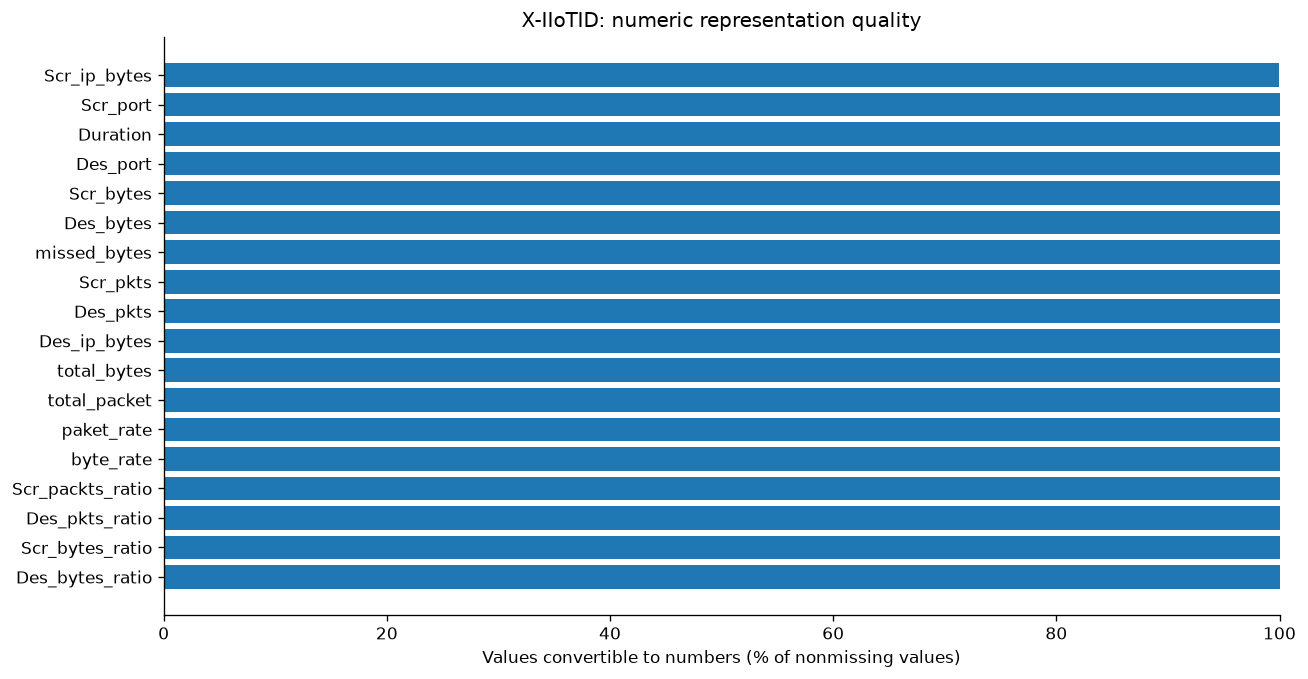

Saved: reports\figures\x_iiotid_numeric_parse_quality_v1.png


In [8]:
quality = inventory[inventory.proposed_role.isin([
    'NETWORK_CORE_CANDIDATE','NETWORK_OPTIONAL_CANDIDATE',
    'PORT_ABLATION_ONLY'])].copy()
quality = quality.sort_values('missing_pct_all_rows', ascending=False)
fig, ax = plt.subplots(figsize=(11, max(6, 0.31 * len(quality))))
ax.barh(quality.original_column[::-1], quality.missing_pct_all_rows[::-1])
ax.set_xlim(0, 100)
ax.set_xlabel('Missing or placeholder values (%) — full CSV')
ax.set_title('X-IIoTID network candidate feature missingness')
fig.tight_layout()
savefig('x_iiotid_network_missingness_v1.png')

validity = inventory[inventory.original_column.isin(numeric_expected)].copy()
validity = validity.sort_values('numeric_parse_pct_among_present')
fig, ax = plt.subplots(figsize=(11, max(5, 0.32 * len(validity))))
ax.barh(validity.original_column[::-1], validity.numeric_parse_pct_among_present[::-1])
ax.set_xlim(0, 100)
ax.set_xlabel('Values convertible to numbers (% of nonmissing values)')
ax.set_title('X-IIoTID: numeric representation quality')
fig.tight_layout()
savefig('x_iiotid_numeric_parse_quality_v1.png')

## D. Exploratory feature collisions and label conflicts

**Feature collision:** different CSV records produce the same selected model input values.  
**Example:** two traffic records could both have `Protocol=tcp`, `Duration=0.1`, `Scr_pkts=2`, etc., even if one is benign and one malicious.

- Large groups and conflicting labels suggest **limited discriminatory information** in this particular feature subset.
- Grouping by a small number of features naturally creates repeated combinations; **this does not prove the entire dataset is unusable**.
- We measure this on a sample only. We will later repeat split-safety checks on the full chosen feature set **before** choosing a 70/15/15 split.

Features used: ['Protocol', 'Service', 'Duration', 'Scr_bytes', 'Des_bytes', 'Scr_pkts', 'Des_pkts', 'Conn_state']
Sample records: 42500
Number of distinct feature combinations: 28403
Sample records in repeated combinations: 16604
Combinations containing BOTH binary labels: 60
Sample records in conflicting-label combinations: 321


,group_size,distinct_labels,Protocol,Service,Duration,Scr_bytes,Des_bytes,Scr_pkts,Des_pkts,Conn_state
0,3226,1,udp,coap,<MISSING>,<MISSING>,<MISSING>,1,0,1
1,222,1,tcp,other,0.000011,0,0,1,1,0
2,119,1,tcp,other,0.000021,0,0,1,1,0
3,114,1,udp,dns,<MISSING>,<MISSING>,<MISSING>,1,0,1
4,108,1,tcp,other,0.000012,0,0,1,1,0
5,100,1,tcp,other,0.000011,<MISSING>,<MISSING>,<MISSING>,<MISSING>,0
6,94,1,udp,dns,0.000006,108,0,2,0,1
7,94,1,tcp,other,0.00002,0,0,1,1,0
8,89,1,tcp,other,0.000022,0,0,1,1,0
9,84,1,udp,dns,0.000006,74,0,2,0,1


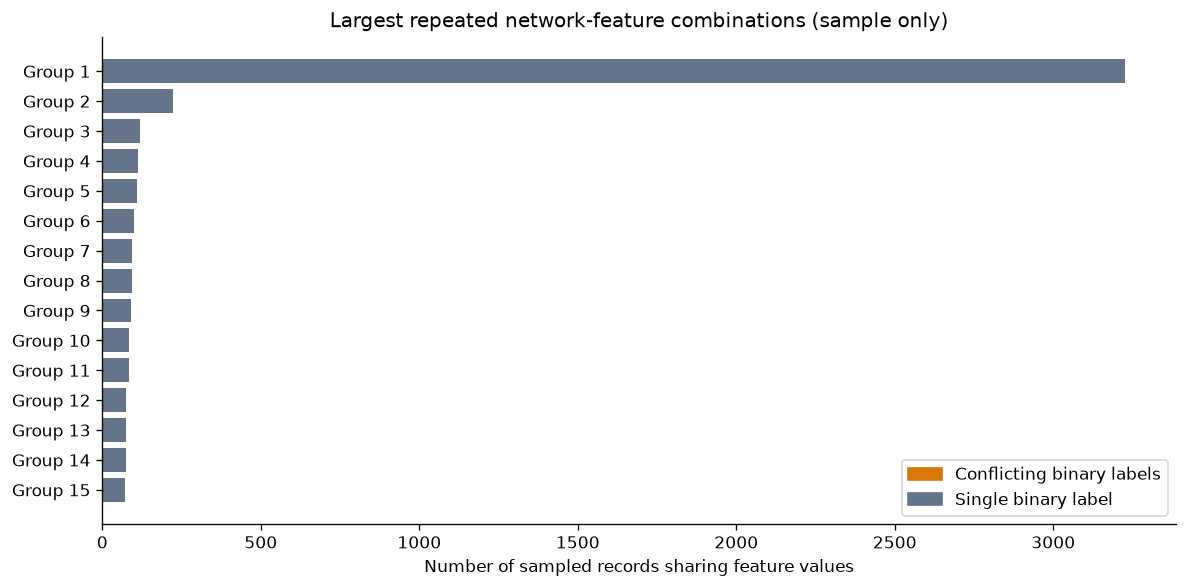

Saved: reports\figures\x_iiotid_sample_feature_collisions_v1.png


In [9]:
collision_names = existing('Protocol','Service','Duration','Scr_bytes',
                            'Des_bytes','Scr_pkts','Des_pkts',
                            'Conn_state')
if len(collision_names) < 3:
    print('Insufficient network columns for exploratory collision diagnostic.')
    group_summary = pd.DataFrame()
else:
    chosen = sample[collision_names].fillna('<MISSING>').copy()
    for col in collision_names:
        chosen[col] = chosen[col].mask(chosen[col].str.lower().isin(PLACEHOLDERS), '<MISSING>')
    chosen['_label'] = sample[lookup['class3']].values
    group_summary = chosen.groupby(collision_names, dropna=False, sort=False).agg(
        group_size=('_label', 'size'),
        distinct_labels=('_label', 'nunique'),
    ).reset_index()
    colliding_records = int(group_summary.loc[group_summary.group_size > 1, 'group_size'].sum())
    conflicting_groups = int((group_summary.distinct_labels > 1).sum())
    conflicting_records = int(group_summary.loc[group_summary.distinct_labels > 1, 'group_size'].sum())
    print('Features used:', collision_names)
    print('Sample records:', len(sample))
    print('Number of distinct feature combinations:', len(group_summary))
    print('Sample records in repeated combinations:', colliding_records)
    print('Combinations containing BOTH binary labels:', conflicting_groups)
    print('Sample records in conflicting-label combinations:', conflicting_records)
    top = group_summary.sort_values('group_size', ascending=False).head(15).reset_index(drop=True)
    display(top[['group_size', 'distinct_labels'] + collision_names])
    fig, ax = plt.subplots(figsize=(10, 5))
    topplot = top.iloc[::-1]
    bars = ax.barh([f'Group {i}' for i in range(len(top), 0, -1)], topplot.group_size,
                   color=['#d97706' if x > 1 else '#64748b' for x in topplot.distinct_labels])
    ax.set_title('Largest repeated network-feature combinations (sample only)')
    ax.set_xlabel('Number of sampled records sharing feature values')
    ax.legend(handles=[
        plt.Rectangle((0,0),1,1,color='#d97706',label='Conflicting binary labels'),
        plt.Rectangle((0,0),1,1,color='#64748b',label='Single binary label')
    ])
    fig.tight_layout()
    savefig('x_iiotid_sample_feature_collisions_v1.png')

,Scr_bytes_ratio,Des_bytes_ratio,total_bytes,byte_rate,Des_bytes,paket_rate,Scr_bytes,Des_pkts,Des_ip_bytes,Scr_ip_bytes,Scr_pkts,total_packet
class3,,,,,,,,,,,,
Attack,34.41,34.41,34.41,34.41,34.41,34.41,34.41,18.69,18.69,18.69,18.69,18.69
Normal,19.22,19.22,19.22,19.22,19.22,19.22,19.22,17.75,17.75,17.75,17.75,17.75


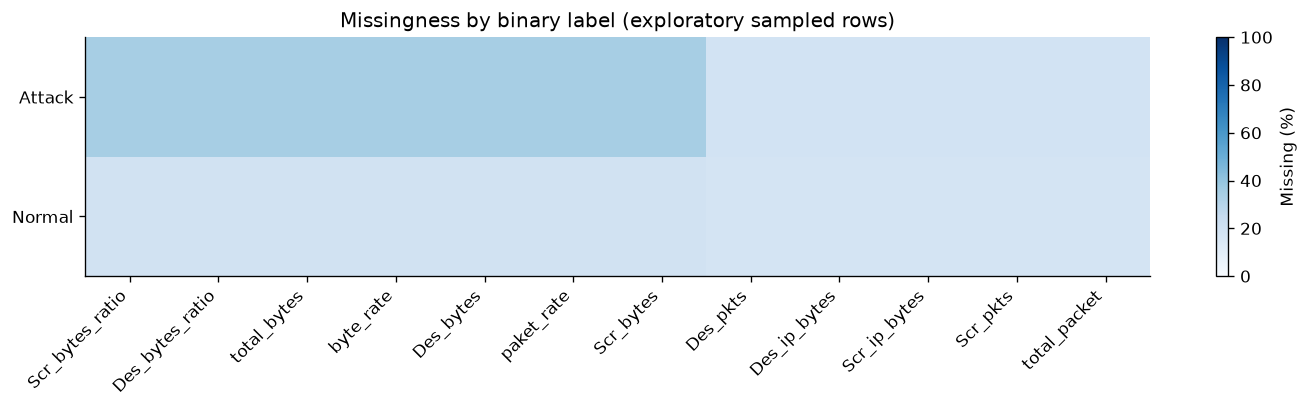

Saved: reports\figures\x_iiotid_missingness_by_binary_label_sample_v1.png


In [10]:
# Optional sixth chart: is feature missingness connected to the binary label?
# This is exploratory evidence of a dataset shortcut, NOT model feature importance.
label = lookup['class3']
if len(network_cols) and 1 < sample[label].nunique() <= 6:
    largest_missing = [c for c in quality.original_column if c in sample.columns][:12]
    sample_miss = sample[largest_missing].apply(
        lambda s: s.str.strip().str.lower().isin(PLACEHOLDERS))
    missing_by_label = sample_miss.groupby(sample[label]).mean().mul(100)
    display(missing_by_label.round(2))
    fig, ax = plt.subplots(figsize=(12, max(3.5, 0.7 * len(missing_by_label))))
    matrix = missing_by_label.to_numpy()
    img = ax.imshow(matrix, aspect='auto', vmin=0, vmax=100, cmap='Blues')
    ax.set_xticks(np.arange(len(missing_by_label.columns)), missing_by_label.columns,
                  rotation=45, ha='right')
    ax.set_yticks(np.arange(len(missing_by_label.index)), missing_by_label.index)
    ax.set_title('Missingness by binary label (exploratory sampled rows)')
    fig.colorbar(img, ax=ax, label='Missing (%)')
    fig.tight_layout()
    savefig('x_iiotid_missingness_by_binary_label_sample_v1.png')
else:
    print('Skipping missingness-by-label plot: insufficient classes or features.')

## E. Export an evidence-based feature inventory

At this point, don't remove features solely based on missing percentage or change names in your raw CSV. The generated audit is a **draft review gate**:

- Verify units, direction, definitions, and whether the Raspberry Pi gateway can measure every candidate.
- Don't train on raw IP addresses, timestamps, existing IDS alerts, labels or host telemetry in your **network-only** classifier.
- After review, make data splits that account for related records / capture sessions; random row splitting can exaggerate performance.
- Later compare all network candidates against a smaller lightweight feature set using validation scores and edge latency.

In [11]:
csv_path = AUDIT / 'x_iiotid_network_feature_participation_v1.csv'
json_path = AUDIT / 'x_iiotid_network_feature_screening_v1.json'
md_path = DOCS / 'X_IIOTID_NETWORK_FEATURE_SCREENING_V1.md'
inventory.to_csv(csv_path, index=False)

summary = {
    'dataset': CSV.name,
    'source_path_not_committed': str(CSV),
    'records_scanned': int(row_total),
    'columns': len(header),
    'sample_records_for_collision_review': int(len(sample)),
    'sample_only_not_for_training': True,
    'label_distributions': {
        label: {str(k): int(v) for k,v in counter.items()}
        for label, counter in label_counts.items()
    },
    'network_core_candidates_actual': core_cols,
    'network_optional_candidates_actual': optional_cols,
    'network_candidates_all': network_cols,
    'numeric_conversion_rate_excludes_placeholders': {
        c: round(float(v), 4) if pd.notna(v) else None
        for c, v in numeric_pct.items()
    },
    'columns_requiring_separate_review': inventory.loc[
        inventory.proposed_role == 'REVIEW_SEPARATELY', 'original_column'
    ].tolist(),
    'collision_diagnostic': {
        'scope': 'sample_only',
        'features': collision_names,
        'groups': int(len(group_summary)),
        'repeated_group_records': int(colliding_records) if len(group_summary) else None,
        'conflicting_label_groups': int(conflicting_groups) if len(group_summary) else None,
        'records_in_conflicting_groups': int(conflicting_records) if len(group_summary) else None,
    },
    'limitations': [
        'No train/validation/test split performed.',
        'Feature semantic compatibility and real gateway extractability not yet verified.',
        'Sample-only collisions must not be interpreted as full-dataset leakage or split feasibility.',
        'No real-time or 5/10/15/20-second windows established.',
        'X-IIoTID attacks do not alone prove full APT campaign detection.',
    ]
}
json_path.write_text(json.dumps(summary, indent=2), encoding='utf-8')

review = inventory[['original_column','proposed_role','missing_pct_all_rows',
                    'numeric_parse_pct_among_present']].copy()
with md_path.open('w', encoding='utf-8') as f:
    f.write('# X-IIoTID network feature screening — draft v1\n\n')
    f.write(f'- Rows: {row_total:,}\n- Columns: {len(header)}\n')
    f.write(f'- Sample for collision diagnostics: {len(sample):,}\n')
    f.write('- Scope: screening only; no selected feature set, leakage-safe split or model trained.\n\n')
    f.write('## Candidate network-feature roles and quality\n\n')
    f.write('| Column | Proposed role | Missing/placeholder % | Numeric parse % of present |\n')
    f.write('|---|---|---:|---:|\n')
    for r in review.itertuples(index=False):
        miss = f'{r.missing_pct_all_rows:.2f}'
        num = f'{r.numeric_parse_pct_among_present:.2f}' if pd.notna(r.numeric_parse_pct_among_present) else '—'
        f.write(f'| `{r.original_column}` | {r.proposed_role} | {miss} | {num} |\n')
    f.write('\n## Next gate\n\n')
    f.write('1. Verify original feature semantics and missing-value meanings.\n')
    f.write('2. Confirm extractability at Raspberry Pi/edge gateway.\n')
    f.write('3. Investigate source/capture-based grouping and leakage-free partitioning.\n')
    f.write('4. Decide network-only compact subset, then 70/15/15, then models.\n')

print('Saved files:')
for p in (csv_path, json_path, md_path):
    print('  ', p.relative_to(ROOT))
print('Saved PNGs:')
for p in sorted(FIG.glob('x_iiotid_*_v1.png')):
    print('  ', p.relative_to(ROOT))
print('\nNEXT GATE: review this output before splitting or modelling.')

Saved files:
   reports\audits\x_iiotid_network_feature_participation_v1.csv
   reports\audits\x_iiotid_network_feature_screening_v1.json
   docs\X_IIOTID_NETWORK_FEATURE_SCREENING_V1.md
Saved PNGs:
   reports\figures\x_iiotid_binary_label_balance_v1.png
   reports\figures\x_iiotid_class2_distribution_v1.png
   reports\figures\x_iiotid_missingness_by_binary_label_sample_v1.png
   reports\figures\x_iiotid_network_missingness_v1.png
   reports\figures\x_iiotid_numeric_parse_quality_v1.png
   reports\figures\x_iiotid_sample_feature_collisions_v1.png

NEXT GATE: review this output before splitting or modelling.


## F. Git checkpoint — only after running and reviewing the results

In **PowerShell terminal** (not a Python notebook cell):

```powershell
Set-Location 'D:\J26-CS-336-Network-Flow-V2-Git'
git branch --show-current
git status --short

git add -- network_flow_v2/notebooks/x_iiotid/03_x_iiotid_network_feature_screening.ipynb
git add -- network_flow_v2/reports/audits/x_iiotid_network_feature_participation_v1.csv
git add -- network_flow_v2/reports/audits/x_iiotid_network_feature_screening_v1.json
git add -- network_flow_v2/reports/figures/x_iiotid_*.png
git add -- network_flow_v2/docs/X_IIOTID_NETWORK_FEATURE_SCREENING_V1.md

git diff --cached --name-only
git diff --cached --check
# Check these are only the intended files and no data/raw content.
git commit -m "research: screen X-IIoTID network features with visual audits"
git push
```

**Share with me:** notebook summary output, top feature missingness, label distribution, and collision diagnostic. We'll then verify which columns truly belong in the network-only first model, compare them with ToN-IoT semantics, and design the split.